# MobileNetV4-Conv-Small — Person-wise Driver Behaviour Classification

This notebook benchmarks **MobileNetV4-Conv-Small** using the same person-wise dataset split, image preprocessing, training settings, metrics, and plotting protocol as the EfficientNetV2-S notebook.

**Person-wise split:** `Train/Person1...Person7`, `Validation/Person8`, `Test/Person9`.

- Uses ImageNet-pretrained MobileNetV4-Conv-Small weights through `timm`.
- Keeps the same five class labels and the same participant-level separation checks.
- Selects the best checkpoint using validation macro-F1.
- Evaluates Person9 only after training is complete.
- Saves metrics, classification report, confusion matrix, and training/validation curves.

**Fair comparison:** Keep the EfficientNetV2-S notebook's split and hyperparameters unchanged. Do not use Person9 results to tune this model.

**Note:** MobileNetV4 is loaded from the `timm` library, not `torchvision`. The pretrained checkpoint may be downloaded on the first run.


## 1. Install dependencies (run once if needed)

In [ ]:
# If timm is not installed in your environment, uncomment and run:
# %pip install -U timm


## 2. Imports

In [3]:
import random
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tqdm import tqdm


## 3. Configuration and reproducibility

In [4]:
# Update this only if your dataset is stored elsewhere.
ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Dataset")

TRAIN_DIR = ROOT_DIR / "Train"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Test"

CLASSES = ["Distraction", "Drinking", "Normal", "Phone", "Sleeping"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

SEED = 42
BATCH_SIZE = 4
NUM_WORKERS = 0
EPOCHS = 25
EARLY_STOPPING_PATIENCE = 6

# Match EfficientNetV2-S notebook preprocessing exactly.
IMAGE_HEIGHT = 384
IMAGE_WIDTH = 684

# Same differential learning rates and regularization as EfficientNetV2-S.
BACKBONE_LR = 3e-5
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

MODEL_NAME = "mobilenetv4_conv_small.e2400_r224_in1k"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("timm version:", timm.__version__)
print("Model:", MODEL_NAME)

for split_name, split_dir in [("Train", TRAIN_DIR), ("Validation", VAL_DIR), ("Test", TEST_DIR)]:
    print(f"{split_name} directory exists:", split_dir.exists())
    if not split_dir.exists():
        raise FileNotFoundError(f"Check dataset path: {split_dir}")


Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
timm version: 1.0.31
Model: mobilenetv4_conv_small.e2400_r224_in1k
Train directory exists: True
Validation directory exists: True
Test directory exists: True


## 4. Build image index and verify person-wise separation

In [6]:
def build_dataframe(split_path):
    rows = []
    person_folders = sorted(p for p in split_path.iterdir() if p.is_dir())

    for person_folder in person_folders:
        person_name = person_folder.name
        for class_name in CLASSES:
            class_folder = person_folder / class_name
            if not class_folder.exists():
                continue
            for image_path in class_folder.iterdir():
                if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    rows.append({
                        "path": str(image_path),
                        "person": person_name,
                        "class": class_name,
                        "label": CLASS_TO_IDX[class_name]
                    })
    return pd.DataFrame(rows)

train_df = build_dataframe(TRAIN_DIR)
val_df = build_dataframe(VAL_DIR)
test_df = build_dataframe(TEST_DIR)

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("At least one split is empty. Check folder structure and class-folder names.")

train_people = set(train_df["person"].unique())
val_people = set(val_df["person"].unique())
test_people = set(test_df["person"].unique())

print("Train images:", len(train_df), "| participants:", sorted(train_people))
print("Validation images:", len(val_df), "| participants:", sorted(val_people))
print("Test images:", len(test_df), "| participants:", sorted(test_people))

assert train_people.isdisjoint(val_people), "Participant leakage between train and validation!"
assert train_people.isdisjoint(test_people), "Participant leakage between train and test!"
assert val_people.isdisjoint(test_people), "Participant leakage between validation and test!"

print("\nParticipant-wise separation check passed.")
print("\nTraining class counts:")
print(train_df["class"].value_counts().reindex(CLASSES, fill_value=0))
print("\nValidation class counts:")
print(val_df["class"].value_counts().reindex(CLASSES, fill_value=0))
print("\nTest class counts:")
print(test_df["class"].value_counts().reindex(CLASSES, fill_value=0))


Train images: 25779 | participants: ['Person1', 'Person2', 'Person3', 'Person4', 'Person5', 'Person6', 'Person7']
Validation images: 3548 | participants: ['Person8']
Test images: 3565 | participants: ['Person9']

Participant-wise separation check passed.

Training class counts:
class
Distraction    4836
Drinking       5736
Normal         4895
Phone          5333
Sleeping       4979
Name: count, dtype: int64

Validation class counts:
class
Distraction    712
Drinking       636
Normal         633
Phone          901
Sleeping       666
Name: count, dtype: int64

Test class counts:
class
Distraction    696
Drinking       642
Normal         709
Phone          819
Sleeping       699
Name: count, dtype: int64


## 5. Image transformations and datasets

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class DriverDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row["path"]) as img:
            image = img.convert("RGB")
        return self.transform(image), int(row["label"])

train_dataset = DriverDataset(train_df, train_transform)
val_dataset = DriverDataset(val_df, eval_transform)
test_dataset = DriverDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))


Batches: 6445 887 892


## 6. Class weights

In [8]:
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"].to_numpy()
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)

print("Class weights:")
for class_name, weight in zip(CLASSES, class_weights_np):
    print(f"{class_name:15s}: {weight:.3f}")


Class weights:
Distraction    : 1.066
Drinking       : 0.899
Normal         : 1.053
Phone          : 0.967
Sleeping       : 1.036


## 7. Load pretrained MobileNetV4-Conv-Small

In [9]:
# timm downloads ImageNet pretrained weights on the first run if not cached.
# num_classes=5 replaces the original ImageNet classifier with a five-class head.
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=len(CLASSES)
)
model = model.to(DEVICE)

# timm exposes the final classifier through get_classifier().
classifier = model.get_classifier()
if not isinstance(classifier, nn.Module):
    raise RuntimeError("Could not identify the MobileNetV4 classifier module.")

head_param_ids = {id(p) for p in classifier.parameters()}
head_params = [p for p in model.parameters() if id(p) in head_param_ids]
backbone_params = [p for p in model.parameters() if id(p) not in head_param_ids]

if not head_params or not backbone_params:
    raise RuntimeError("Could not separate backbone and classifier parameters.")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model.get_classifier())
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Backbone tensors: {len(backbone_params)} | classifier tensors: {len(head_params)}")


c:\Btech\SEM5\cuda\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rakes\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Linear(in_features=1280, out_features=5, bias=True)
Total parameters: 2,499,429
Trainable parameters: 2,499,429
Backbone tensors: 138 | classifier tensors: 2


c:\Btech\SEM5\cuda\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rakes\.cache\huggingface\hub\models--timm--mobilenetv4_conv_small.e2400_r224_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 8. Loss, optimizer, scheduler and AMP

In [10]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": BACKBONE_LR},
        {"params": head_params, "lr": HEAD_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2,
    threshold=1e-3, min_lr=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Backbone LR:", BACKBONE_LR)
print("Classifier LR:", HEAD_LR)
print("AMP enabled:", USE_AMP)


Backbone LR: 3e-05
Classifier LR: 0.0003
AMP enabled: True


## 9. Training and validation

In [11]:
RESULTS_DIR = Path("MobileNetV4_Conv_Small_Personwise_Results")
RESULTS_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = RESULTS_DIR / "best_mobilenetv4_conv_small_personwise.pth"

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_f1": [], "val_f1": []
}

best_val_f1 = -1.0
epochs_without_improvement = 0
best_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 60)

    # TRAIN
    model.train()
    running_loss = 0.0
    train_true, train_pred = [], []

    for images, labels in tqdm(train_loader, desc="Training", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(preds.detach().cpu().numpy())

    train_loss = running_loss / max(1, len(train_loader))
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(train_true, train_pred, average="macro", zero_division=0)

    # VALIDATION
    model.eval()
    val_running_loss = 0.0
    val_true, val_pred = [], []

    with torch.inference_mode():
        for images, labels in tqdm(val_loader, desc="Validation", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            preds = outputs.argmax(dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0)

    scheduler.step(val_f1)
    current_lrs = [group["lr"] for group in optimizer.param_groups]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        best_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_state,
            "classes": CLASSES,
            "class_to_idx": CLASS_TO_IDX,
            "best_val_macro_f1": best_val_f1,
            "image_size": (IMAGE_HEIGHT, IMAGE_WIDTH),
            "architecture": MODEL_NAME,
            "timm_version": timm.__version__
        }, CHECKPOINT_PATH)
        status = "Best checkpoint saved"
    else:
        epochs_without_improvement += 1
        status = f"No improvement: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"

    elapsed = time.time() - epoch_start
    print(f"Train | loss {train_loss:.4f} | acc {train_acc:.4f} | macro-F1 {train_f1:.4f}")
    print(f"Val   | loss {val_loss:.4f} | acc {val_acc:.4f} | macro-F1 {val_f1:.4f}")
    print(f"LR backbone: {current_lrs[0]:.2e} | head: {current_lrs[1]:.2e}")
    print(f"{status} | epoch time: {elapsed/60:.1f} min")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping.")
        break

print("\nTraining finished.")
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print("Checkpoint:", CHECKPOINT_PATH.resolve())



Epoch [1/25]
------------------------------------------------------------


Train | loss 1.6024 | acc 0.4712 | macro-F1 0.4714
Val   | loss 1.2518 | acc 0.5682 | macro-F1 0.5298
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 10.2 min

Epoch [2/25]
------------------------------------------------------------


Train | loss 0.9298 | acc 0.7233 | macro-F1 0.7231
Val   | loss 1.1288 | acc 0.6130 | macro-F1 0.6002
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 9.8 min

Epoch [3/25]
------------------------------------------------------------


Train | loss 0.7497 | acc 0.7997 | macro-F1 0.7993
Val   | loss 1.0139 | acc 0.6280 | macro-F1 0.6137
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 9.6 min

Epoch [4/25]
------------------------------------------------------------


Train | loss 0.6553 | acc 0.8406 | macro-F1 0.8401
Val   | loss 1.0747 | acc 0.6437 | macro-F1 0.6283
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 10.5 min

Epoch [5/25]
------------------------------------------------------------


Train | loss 0.5905 | acc 0.8635 | macro-F1 0.8630
Val   | loss 1.1438 | acc 0.6463 | macro-F1 0.6051
LR backbone: 3.00e-05 | head: 3.00e-04
No improvement: 1/6 | epoch time: 12.3 min

Epoch [6/25]
------------------------------------------------------------


... (9 outputs left out)

Train | loss 0.3772 | acc 0.9404 | macro-F1 0.9402
Val   | loss 0.9990 | acc 0.6618 | macro-F1 0.6312
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 3/6 | epoch time: 9.3 min

Epoch [16/25]
------------------------------------------------------------


Train | loss 0.3586 | acc 0.9465 | macro-F1 0.9463
Val   | loss 0.9604 | acc 0.7069 | macro-F1 0.6913
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 4/6 | epoch time: 9.3 min

Epoch [17/25]
------------------------------------------------------------


Train | loss 0.3493 | acc 0.9498 | macro-F1 0.9498
Val   | loss 0.9887 | acc 0.6773 | macro-F1 0.6550
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 5/6 | epoch time: 9.3 min

Epoch [18/25]
------------------------------------------------------------


Train | loss 0.3482 | acc 0.9521 | macro-F1 0.9520
Val   | loss 0.9643 | acc 0.6866 | macro-F1 0.6626
LR backbone: 7.50e-06 | head: 7.50e-05
No improvement: 6/6 | epoch time: 9.4 min
Early stopping.

Training finished.
Best validation macro-F1: 0.7319
Checkpoint: C:\Btech\SEM5\cuda\DL\MobileNetV4_Conv_Small_Personwise_Results\best_mobilenetv4_conv_small_personwise.pth


## 10. Load best checkpoint and evaluate the test participant once

In [12]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_true, test_pred = [], []

with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        test_pred.extend(preds)
        test_true.extend(labels.numpy())

test_accuracy = accuracy_score(test_true, test_pred)
test_precision = precision_score(test_true, test_pred, average="macro", zero_division=0)
test_recall = recall_score(test_true, test_pred, average="macro", zero_division=0)
test_macro_f1 = f1_score(test_true, test_pred, average="macro", zero_division=0)

print("PERSON-WISE TEST RESULTS")
print(f"Accuracy       : {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall   : {test_recall:.4f}")
print(f"Macro F1       : {test_macro_f1:.4f}")

report = classification_report(
    test_true, test_pred, target_names=CLASSES,
    digits=4, zero_division=0, output_dict=True
)
report_df = pd.DataFrame(report).transpose()
display(report_df)
report_df.to_csv(RESULTS_DIR / "classification_report.csv")

cm = confusion_matrix(test_true, test_pred, labels=np.arange(len(CLASSES)))
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(RESULTS_DIR / "confusion_matrix.csv")

metrics_df = pd.DataFrame([{
    "Model": "MobileNetV4-Conv-Small",
    "Protocol": "Person-wise (Person9 test)",
    "Accuracy": test_accuracy,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1": test_macro_f1
}])
display(metrics_df)
metrics_df.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)


Testing: 100%|██████████| 892/892 [00:27<00:00, 31.87it/s]

PERSON-WISE TEST RESULTS
Accuracy       : 0.8317
Macro Precision: 0.8519
Macro Recall   : 0.8399
Macro F1       : 0.8351


,precision,recall,f1-score,support
Distraction,0.907967,0.949713,0.928371,696.000000
Drinking,0.912782,0.945483,0.928845,642.000000
Normal,0.654244,0.891396,0.754627,709.000000
Phone,0.979630,0.645910,0.778514,819.000000
Sleeping,0.804805,0.766810,0.785348,699.000000
accuracy,0.831697,0.831697,0.831697,0.831697
macro avg,0.851886,0.839862,0.835141,3565.000000
weighted avg,0.854610,0.831697,0.831432,3565.000000


,Model,Protocol,Accuracy,Macro Precision,Macro Recall,Macro F1
0,MobileNetV4-Conv-Small,Person-wise (Person9 test),0.831697,0.851886,0.839862,0.835141


## 11. Save training curves and confusion matrix

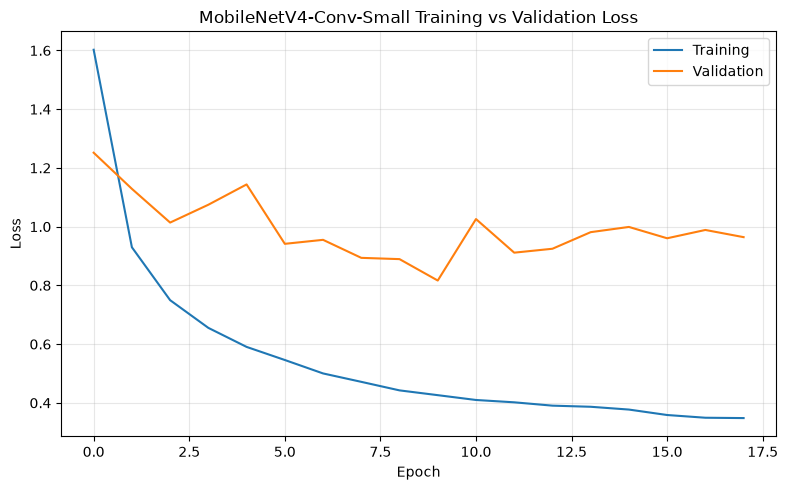

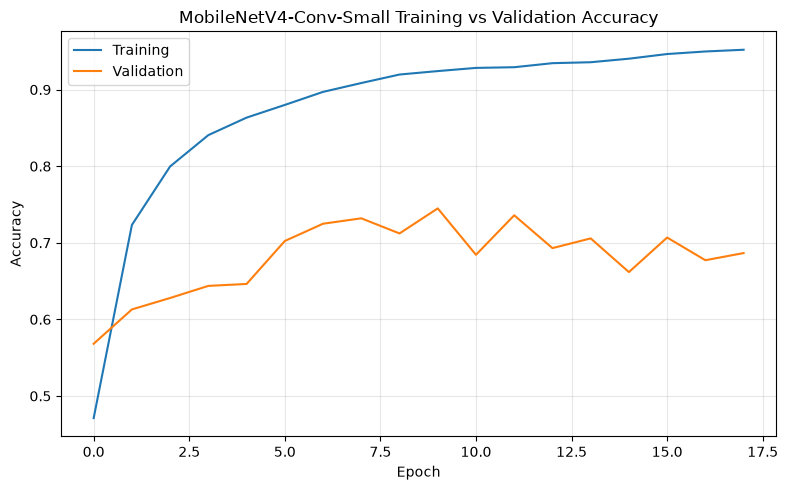

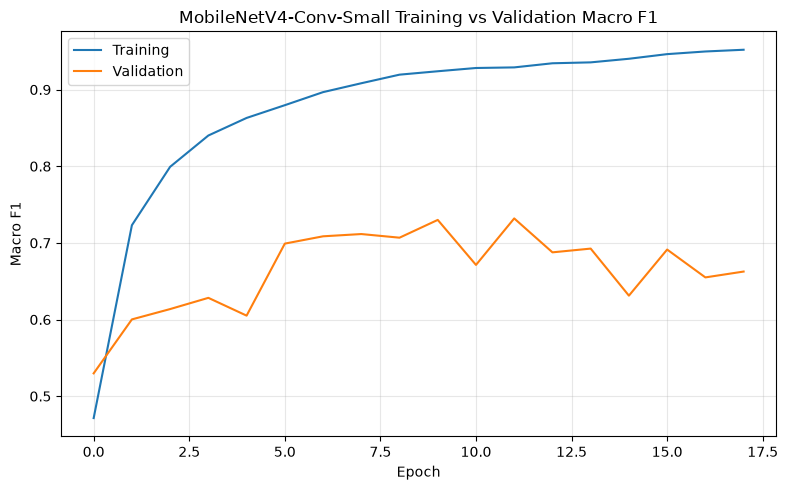

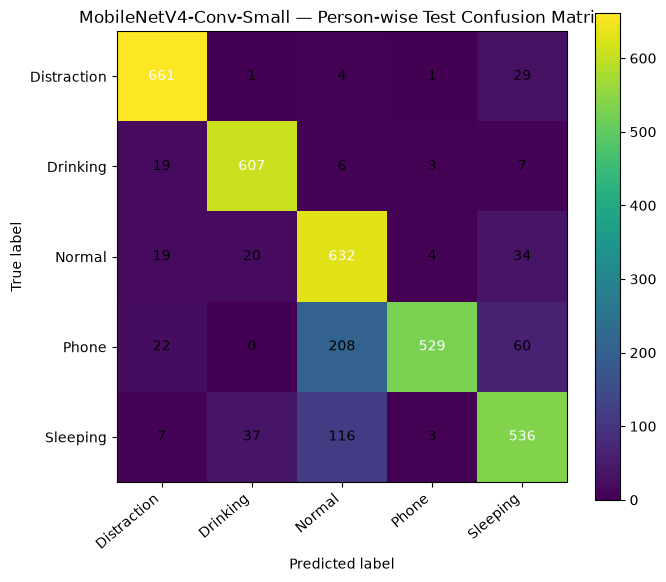

All results saved in: C:\Btech\SEM5\cuda\DL\MobileNetV4_Conv_Small_Personwise_Results


In [13]:
def save_curve(train_values, val_values, title, ylabel, filename):
    plt.figure(figsize=(8, 5))
    plt.plot(train_values, label="Training")
    plt.plot(val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=300)
    plt.show()

save_curve(history["train_loss"], history["val_loss"],
           "MobileNetV4-Conv-Small Training vs Validation Loss", "Loss", "loss_curve.png")
save_curve(history["train_acc"], history["val_acc"],
           "MobileNetV4-Conv-Small Training vs Validation Accuracy", "Accuracy", "accuracy_curve.png")
save_curve(history["train_f1"], history["val_f1"],
           "MobileNetV4-Conv-Small Training vs Validation Macro F1", "Macro F1", "macro_f1_curve.png")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("MobileNetV4-Conv-Small — Person-wise Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=40, ha="right")
ax.set_yticklabels(CLASSES)

threshold = cm.max() / 2 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")

fig.colorbar(im)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

print("All results saved in:", RESULTS_DIR.resolve())


## 12. Important notes for a fair comparison

1. This notebook uses the same person-wise split as EfficientNetV2-S: training participants, validation participant, and held-out test participant must remain separate.
2. The same image size, augmentations, normalization, batch size, maximum epochs, early stopping, optimizer, learning rates, weight decay, label smoothing, scheduler, and metrics are retained.
3. MobileNetV4-Conv-Small is loaded using `timm`. Record the exact `timm`, PyTorch, and torchvision versions.
4. The pretrained checkpoint name is `mobilenetv4_conv_small.e2400_r224_in1k`. If your installed `timm` version does not recognize it, update `timm` and check `timm.list_models("*mobilenetv4*")`.
5. If CUDA runs out of memory, reduce `BATCH_SIZE` from 4 to 2 in both model experiments for a fair comparison. Do not increase it solely to raise GPU utilization.
6. Do not use Person9 test results to select epochs, learning rates, or architectures.
7. The same hyperparameters make the comparison controlled, but do not guarantee that each architecture is individually optimally tuned. State this clearly in your report.
8. For a publication-quality comparison, report training time, parameter count, inference latency, and the same test metrics for every architecture.
